# Módulo 13 — Calibração I: a curva de juros no CIR e as opções no Heston

## Introdução

Calibrar é escolher os parâmetros de um modelo para que seus preços reproduzam os preços observados no mercado. Este capítulo trata os dois blocos mais importantes do BCC97 separadamente.

O primeiro é a **curva de juros**. No modelo CIR, a curva de juros gerada pelo modelo depende de quatro parâmetros, e o primeiro exercício é ajustá-la a uma curva de mercado, entendendo o que o modelo consegue e não consegue reproduzir. O segundo bloco são as **opções**: o modelo de Heston é calibrado a uma superfície de preços de opções por mínimos quadrados, usando a fórmula de Lewis.

A calibração parece um simples problema de otimização, mas não é. A função objetivo tem vales longos, nos quais parâmetros bem diferentes produzem quase o mesmo ajuste; restrições como a condição de Feller ficam ativas; e o otimizador pode parar em mínimos locais. O capítulo mostra esses fenômenos com dados sintéticos, nos quais os parâmetros verdadeiros são conhecidos, e discute o que a calibração consegue e não consegue identificar.

**Curso:** Derivativos com Python, a partir de *Derivatives Analytics with Python* (Y. Hilpisch, Wiley, 2015).
**Este módulo cobre:** capítulo 11 do livro, §11.1 a §11.4.3 (a calibração dos saltos e do BCC97 completo fica para o Módulo 14).

## O que você vai conseguir fazer ao final

1. Explicar por que, num mercado incompleto, o preço depende de uma escolha de medida, e por que a calibração faz essa escolha.
2. Comparar as funções objetivo usuais e saber o que cada uma pondera.
3. Transformar taxas de mercado monetário em taxas contínuas e a termo, e calibrar o CIR à curva.
4. Deduzir a taxa forward do CIR e encontrar um erro na fórmula do livro.
5. Calibrar o Heston a 15 opções com a estratégia do livro: busca em grade e depois busca local.
6. Diagnosticar quais parâmetros os dados de fato identificam, e o que a condição de Feller faz com o ajuste.

## Onde estamos

Os Módulos 7 a 11 entregaram preços a partir de parâmetros. Calibrar é o caminho inverso: partir dos preços de mercado e chegar aos parâmetros. O livro usa dados reais (Euribor e opções do EURO STOXX 50 de 30/09/2014). Aqui, como em todo o curso, usamos **dados sintéticos** com a mesma estrutura: 9 taxas de 1 dia a 1 ano e 15 calls em 3 vencimentos e 5 strikes. A vantagem é poder comparar o calibrado com o verdadeiro, o que nenhum dado real permite.

## 0. Preparação

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.interpolate as sci
from scipy.integrate import simpson
from scipy.optimize import brentq, brute, fmin, linprog
from scipy.stats import norm
from IPython.display import display

AZUL, LARANJA, VERDE, CINZA = "#2a78d6", "#eb6834", "#1baf7a", "#8a8a84"
RAMPA = ["#86b6ef", "#2a78d6", "#104281"]

plt.rcParams.update({
    "figure.figsize": (7.2, 4.0), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5df", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "lines.linewidth": 2.0, "legend.frameon": False,
    "font.size": 10,
})


def f3(x):
    """Formata com três casas decimais no padrão brasileiro."""
    return f"{x:,.3f}".replace(",", "§").replace(".", ",").replace("§", ".")


def tabela(df):
    """Exibe um DataFrame com os números reais em três casas decimais."""
    def fmt(v):
        if isinstance(v, (float, np.floating)):
            return "n/d" if np.isnan(v) else f3(v)
        return v
    display(df.map(fmt))


_checks = {"n": 0}


def ok(condicao, mensagem):
    """Verificação do laboratório: interrompe o notebook se a conta não fechar."""
    assert bool(condicao), f"FALHOU: {mensagem}"
    _checks["n"] += 1
    print(f"OK — {mensagem}")


def bsm(S, K, T, r, sig):
    d1 = (np.log(S / K) + (r + 0.5 * sig**2) * T) / (sig * np.sqrt(T))
    return S * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d1 - sig * np.sqrt(T))


def vega_bsm(S, K, T, r, sig):
    d1 = (np.log(S / K) + (r + 0.5 * sig**2) * T) / (sig * np.sqrt(T))
    return S * norm.pdf(d1) * np.sqrt(T)


def vol_impl(preco, S, K, T, r):
    piso = max(S - K * np.exp(-r * T), 0.0)
    if not (piso + 1e-12 < preco < S):
        return np.nan
    return brentq(lambda s: float(bsm(S, K, T, r, s)) - preco, 1e-4, 4.0)


def cf_heston(u, T, v0, kappa, theta, sigma, rho):
    """Função característica de ln(S_T/S_0) - rT no Heston, forma estável (Módulo 11)."""
    xi = kappa - rho * sigma * 1j * u
    d = np.sqrt(xi**2 + sigma**2 * (1j * u + u**2))
    g = (xi - d) / (xi + d)
    e = np.exp(-d * T)
    A = kappa * theta / sigma**2 * ((xi - d) * T - 2 * np.log((1 - g * e) / (1 - g)))
    B = (xi - d) / sigma**2 * (1 - e) / (1 - g * e)
    return np.exp(A + B * v0)


def cf_saltos(u, T, lam, mu, delta):
    """Parte de saltos de Merton, com o drift compensado (11.13)-(11.14)."""
    omega = -lam * (np.exp(mu + 0.5 * delta**2) - 1)
    return np.exp((1j * u * omega + lam * (np.exp(1j * u * mu - 0.5 * u**2 * delta**2) - 1)) * T)


U_FINO = np.linspace(0, 2000, 200_001)
U_CAL = np.linspace(0, 300, 3001)


def calls(S0, K, T, r, heston, saltos=None, u=U_CAL):
    """Calls europeias pela fórmula de Lewis (11.12), vetorizada em (K, T, r) do mesmo tamanho.
    heston = (v0, κ_v, θ_v, σ_v, ρ); saltos = (λ, μ_J, δ) ou None."""
    K, T, r = (np.atleast_1d(np.asarray(x, float)) for x in (K, T, r))
    k = np.log(S0 / K) + r * T
    phi = cf_heston(u[None, :] - 0.5j, T[:, None], *heston)
    if saltos is not None:
        phi = phi * cf_saltos(u[None, :] - 0.5j, T[:, None], *saltos)
    h = np.exp(1j * u[None, :] * k[:, None]) * phi
    integral = simpson(h.real / (u**2 + 0.25), x=u, axis=1)
    return S0 - np.sqrt(S0 * K) * np.exp(-0.5 * r * T) / np.pi * integral


def zcb_cir(r0, kappa, theta, sigma, T):
    """Zero-cupom no CIR, (11.7)-(11.9) com t = 0."""
    g = np.sqrt(kappa**2 + 2 * sigma**2)
    e = np.exp(g * T) - 1
    D = 2 * g + (kappa + g) * e
    return (2 * g * np.exp((kappa + g) * T / 2) / D) ** (2 * kappa * theta / sigma**2) * np.exp(-2 * e / D * r0)


print("Ambiente pronto.")

Ambiente pronto.


---
## 1. Por que calibrar?

**Livro: §11.1 e §11.2.1**

### 1.1 A ideia

Na visão antiga, os parâmetros vêm primeiro (estimados de séries históricas) e o preço vem depois. Na precificação calibrada ao mercado (Módulo 1), a ordem se inverte: os preços das opções líquidas são dados, e procuramos os parâmetros que os reproduzem. Só então o modelo é usado para o que não tem preço observável.

### 1.2 Mercados incompletos

O BSM é completo: toda opção é replicável com o índice e o título. O Heston é incompleto com o índice apenas, mas completo se uma segunda opção for negociada (há duas fontes de risco). O Merton é incompleto mesmo com todas as opções: o tamanho do salto é aleatório, e seria preciso um continuum de ativos para cobri-lo. O BCC97 herda essa incompletude.

Num mercado incompleto há infinitas medidas $Q$ sem arbitragem e, portanto, um **intervalo** de preços para cada derivativo (Módulo 3, Seção 9). A calibração escolhe, dentro dessa família, a medida que reprecifica as opções observadas. Como diz Björk, citado no livro: quem escolhe a medida martingal é o mercado.

### 1.3 O Exemplo 4 do livro

Um período, três estados equiprováveis, $r = 0$. O título custa 10 e paga 10. O índice custa 10 e paga $(20, 10, 0)$. O derivativo paga $A_1 = (16, 4, 0)$.

**Passo 1 — as medidas.** $Q = (q_1, q_2, q_3)$ precisa de $q_s > 0$, soma 1 e $\mathbb{E}^Q[S_1] = S_0$:

$$20q_1 + 10q_2 = 10 \;\Rightarrow\; q_2 = 1 - 2q_1, \qquad q_1 + q_2 + q_3 = 1 \;\Rightarrow\; q_3 = q_1.$$

Com $q_1 = \nu$, a família é $Q_\nu = (\nu,\, 1 - 2\nu,\, \nu)$, e a positividade exige $0 < \nu < 1/2$.

**Passo 2 — os preços.** $A_0(\nu) = 16\nu + 4(1 - 2\nu) = 4 + 8\nu$, que percorre o intervalo aberto $]4,\ 8[$.

> **Errata.** O livro escreve o limite de $\nu$ como $1/4$ e calcula o preço superior como "$1 + 8 = 9$". Os dois estão errados: a positividade de $q_2 = 1 - 2\nu$ só exige $\nu < 1/2$, e o preço em $\nu = 1/4$ seria $4 + 2 = 6$, não 9. O intervalo correto é $]4, 8[$.

### Laboratório 1 — O intervalo por programação linear

Os extremos do intervalo são os preços de **super-replicação** e **sub-replicação**: o menor custo de uma carteira (título, índice) que paga pelo menos $A_1$ em todos os estados, e o maior custo de uma que paga no máximo $A_1$. São dois problemas de programação linear.

In [2]:
S1 = np.array([20.0, 10.0, 0.0])
B1 = np.array([10.0, 10.0, 10.0])
A1 = np.array([16.0, 4.0, 0.0])
X = np.column_stack([B1, S1])                  # payoffs de (título, índice)
custo = np.array([10.0, 10.0])                 # preços de hoje

sup = linprog(custo, A_ub=-X, b_ub=-A1, bounds=[(None, None)] * 2)    # X·h ≥ A1, custo mínimo
inf = linprog(-custo, A_ub=X, b_ub=A1, bounds=[(None, None)] * 2)     # X·h ≤ A1, custo máximo
print("super-replicação:", f3(sup.fun), "com (título, índice) =", [f3(x) for x in sup.x])
print("sub-replicação:  ", f3(-inf.fun), "com (título, índice) =", [f3(x) for x in inf.x])

nus = np.linspace(0.001, 0.499, 500)
precos_nu = 4 + 8 * nus
ok(abs(sup.fun - 8) < 1e-8 and abs(-inf.fun - 4) < 1e-8, "o intervalo sem arbitragem é ]4, 8[")
ok(np.all((nus > 0) & (1 - 2 * nus > 0)), "todas as medidas com 0 < ν < 1/2 são positivas")
ok(abs(16 * 0.25 + 4 * 0.5 - 6) < 1e-12, "em ν = 1/4, o preço é 6, não 9 como no livro")

super-replicação: 8,000 com (título, índice) = ['-0,000', '0,800']
sub-replicação:   4,000 com (título, índice) = ['-0,000', '0,400']
OK — o intervalo sem arbitragem é ]4, 8[
OK — todas as medidas com 0 < ν < 1/2 são positivas
OK — em ν = 1/4, o preço é 6, não 9 como no livro


O mercado tem um ativo arriscado e três estados: falta um ativo para completá-lo. Se a opção $A$ fosse negociada a, digamos, 6, só a medida $\nu = 1/4$ seria compatível com esse preço. Essa é a calibração em miniatura: **usar preços observados para escolher $Q$**.

---
## 2. Qual função objetivo?

**Livro: §11.2.3**

Com preços de mercado $C_n^*$ e de modelo $C_n(p)$, as três escolhas mais comuns (Christoffersen e Jacobs, 2004) são

$$\text{(11.1)}\ \frac1N\sum_n\big(C_n^* - C_n(p)\big)^2, \qquad
\text{(11.2)}\ \frac1N\sum_n\Big(\frac{C_n^* - C_n(p)}{C_n^*}\Big)^2, \qquad
\text{(11.3)}\ \frac1N\sum_n\big(\sigma_n^* - \sigma_n(p)\big)^2.$$

O livro acrescenta uma versão de (11.3) ponderada pelo vega:

$$\text{(11.4)}\ \frac1N\sum_n\Big((\sigma_n^* - \sigma_n(p))\,\mathcal V_n\Big)^2, \qquad \mathcal V_n = \frac{\partial C^{BSM}}{\partial\sigma}\Big|_{\sigma_n^*}.$$

### 2.1 Por que (11.4) é quase (11.1)

Pela definição de volatilidade implícita, $C_n(p) = C^{BSM}(\sigma_n(p))$ e $C_n^* = C^{BSM}(\sigma_n^*)$. Expandindo em torno de $\sigma_n^*$:

$$C_n^* - C_n(p) \approx \mathcal V_n\,(\sigma_n^* - \sigma_n(p)).$$

Para erros pequenos, (11.4) e (11.1) medem a mesma coisa. A diferença real está entre (11.1)/(11.4), que pesam mais as opções com vega alto (no dinheiro, prazos longos), e (11.3), que pesa igualmente cada ponto da superfície de volatilidade. (11.2) dá peso enorme às opções baratas, fora do dinheiro.

### Laboratório 2 — O que cada função pondera

Montamos o mercado sintético do módulo e perturbamos o modelo verdadeiro (variância inicial 10% maior). Medimos quanto cada opção contribui para cada função objetivo.

#### O mercado sintético

* Índice: $S_0 = 3.225{,}93$ (o nível do EURO STOXX 50 no livro).
* Vencimentos: 17, 80 e 171 dias (os do livro, em base 365).
* Strikes: 3.000 a 3.400, de 100 em 100: 15 calls.
* Modelo "verdadeiro": **Bates** (Heston com saltos de Merton), $v_0 = 0{,}03$, $\kappa_v = 3$, $\theta_v = 0{,}04$, $\sigma_v = 0{,}5$, $\rho = -0{,}7$, $\lambda = 0{,}15$, $\mu_J = -0{,}15$, $\delta = 0{,}1$. O mercado real tem saltos; o Heston que vamos calibrar não tem.
* Juros: os da curva CIR sintética da Seção 3 (definida já aqui).
* Cotações arredondadas a 0,1 ponto, o passo de cotação da Eurex.

In [3]:
S0 = 3225.93
DIAS = np.array([17, 80, 171])
STRIKES = np.arange(3000, 3401, 100.0)
T_OP = np.repeat(DIAS / 365, 5)
K_OP = np.tile(STRIKES, 3)

CIR_VERDADE = dict(r0=0.02, kappa=0.5, theta=0.045, sigma=0.08)      # curva sintética
R_OP = -np.log(zcb_cir(T=T_OP, **CIR_VERDADE)) / T_OP                 # r̄(T) = -ln B0(T)/T

HESTON_VERDADE = (0.03, 3.0, 0.04, 0.5, -0.7)
SALTOS_VERDADE = (0.15, -0.15, 0.10)
C_JUSTO = calls(S0, K_OP, T_OP, R_OP, HESTON_VERDADE, SALTOS_VERDADE, U_FINO)
C_MERC = np.round(C_JUSTO, 1)

ok(np.abs(calls(S0, K_OP, T_OP, R_OP, HESTON_VERDADE, SALTOS_VERDADE) - C_JUSTO).max() < 1e-3,
   "a grade de integração da calibração (0 a 300) erra menos de 0,001 ponto")

IV_MERC = np.array([vol_impl(c, S0, k, t, r) for c, k, t, r in zip(C_MERC, K_OP, T_OP, R_OP)])
mercado = pd.DataFrame({"dias": np.repeat(DIAS, 5), "K": K_OP, "r̄ (%)": 100 * R_OP,
                        "call": C_MERC, "vol. implícita (%)": 100 * IV_MERC})
tabela(mercado)

OK — a grade de integração da calibração (0 a 300) erra menos de 0,001 ponto


,dias,K,r̄ (%),call,vol. implícita (%)
0,17,"3.000,000","2,029","233,200","22,686"
1,17,"3.100,000","2,029","141,900","20,241"
2,17,"3.200,000","2,029","66,300","18,269"
3,17,"3.300,000","2,029","19,400","16,569"
4,17,"3.400,000","2,029","2,600","15,094"
5,80,"3.000,000","2,132","279,000","21,356"
6,80,"3.100,000","2,132","201,300","20,043"
7,80,"3.200,000","2,132","133,500","18,695"
8,80,"3.300,000","2,132","78,700","17,350"
9,80,"3.400,000","2,132","39,500","16,073"


,opção,(11.1) preço,(11.2) relativo,(11.3) vol.,(11.4) vol. × vega
0,17d K=3000,"0,002","0,000","0,044","0,002"
1,17d K=3100,"0,012","0,001","0,081","0,011"
2,17d K=3200,"0,039","0,010","0,119","0,039"
3,17d K=3300,"0,034","0,096","0,135","0,033"
4,17d K=3400,"0,005","0,776","0,143","0,004"
5,80d K=3000,"0,043","0,001","0,051","0,043"
6,80d K=3100,"0,070","0,002","0,056","0,070"
7,80d K=3200,"0,101","0,006","0,064","0,101"
8,80d K=3300,"0,115","0,020","0,072","0,116"
9,80d K=3400,"0,094","0,065","0,080","0,093"


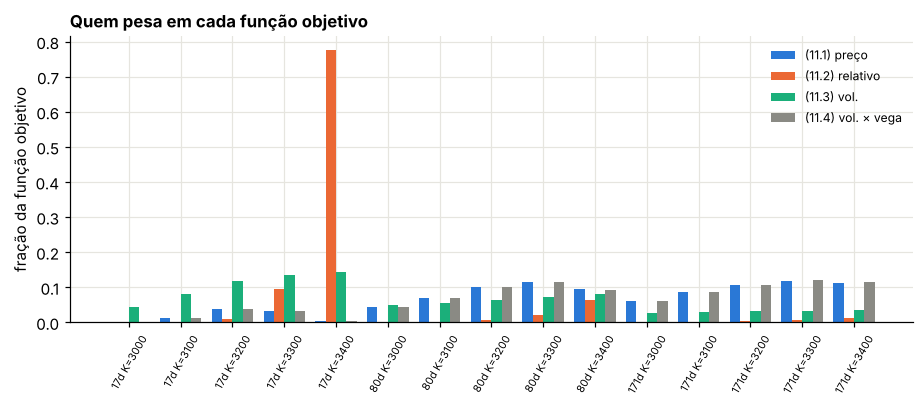

(11.4)/(11.1): 0,995
OK — para erros pequenos, (11.4) e (11.1) coincidem a menos de 5%
OK — o erro relativo concentra mais da metade do peso na call de 17 dias mais fora do dinheiro


In [4]:
pert = (0.033,) + HESTON_VERDADE[1:]
C_pert = calls(S0, K_OP, T_OP, R_OP, pert, SALTOS_VERDADE)
IV_pert = np.array([vol_impl(c, S0, k, t, r) for c, k, t, r in zip(C_pert, K_OP, T_OP, R_OP)])
VEGA = vega_bsm(S0, K_OP, T_OP, R_OP, IV_MERC)

termos = pd.DataFrame({
    "(11.1) preço": (C_MERC - C_pert) ** 2,
    "(11.2) relativo": ((C_MERC - C_pert) / C_MERC) ** 2,
    "(11.3) vol.": (IV_MERC - IV_pert) ** 2,
    "(11.4) vol. × vega": ((IV_MERC - IV_pert) * VEGA) ** 2,
})
pesos = termos / termos.sum()
pesos.insert(0, "opção", [f"{d}d K={k:.0f}" for d, k in zip(np.repeat(DIAS, 5), K_OP)])
tabela(pesos)

fig, ax = plt.subplots(figsize=(8.5, 3.8))
x = np.arange(15)
for j, (col, cor) in enumerate(zip(termos.columns, [AZUL, LARANJA, VERDE, CINZA])):
    ax.bar(x + (j - 1.5) * 0.2, pesos[col], 0.2, color=cor, label=col)
ax.set_xticks(x, pesos["opção"], rotation=60, fontsize=7)
ax.set_ylabel("fração da função objetivo")
ax.set_title("Quem pesa em cada função objetivo")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

razao = termos["(11.4) vol. × vega"].sum() / termos["(11.1) preço"].sum()
print("(11.4)/(11.1):", f3(razao))
ok(abs(razao - 1) < 0.05, "para erros pequenos, (11.4) e (11.1) coincidem a menos de 5%")
ok(pesos["(11.2) relativo"].iloc[4] > 0.5, "o erro relativo concentra mais da metade do peso na call de 17 dias mais fora do dinheiro")

O erro relativo (11.2) é dominado por uma única opção, a call barata de 17 dias com $K = 3.400$, que vale poucos pontos. Já (11.1) e (11.4) quase coincidem e espalham o peso pelas opções de vega alto. O livro usa (11.1) para calibrar a preços e (11.4) para calibrar a volatilidades (Módulo 14).

---
## 3. A curva de juros: calibrar o CIR

**Livro: §11.3 e §11.6.1**

### 3.1 De taxas de mercado monetário a taxas forward

Taxas como a Euribor são **simples**, com contagem real/360: quem aplica 1 por $t$ anos recebe $1 + tL$. O zero-cupom vale $B_0(t) = 1/(1 + tL)$, e a taxa contínua equivalente é

$$y(t) = -\frac{\ln B_0(t)}{t} = \frac{\ln(1 + tL)}{t}.$$

A taxa forward instantânea é $f(0, T) = -\partial_T\ln B_0(T)$. Como $\ln B_0(T) = -T\,y(T)$, derivando o produto:

$$f(0, T) = y(T) + T\,y'(T). \tag{11.10}$$

As taxas só existem em 9 prazos. O livro interpola $y$ por spline cúbico e deriva o spline para obter $f$ em 24 pontos de $[0, 1]$.

### 3.2 A taxa forward no CIR, passo a passo

Do Módulo 11, com $\gamma = \sqrt{\kappa^2 + 2\sigma^2}$, $E = e^{\gamma T} - 1$ e $D = 2\gamma + (\kappa + \gamma)E$:

$$\ln B_0(T) = \frac{2\kappa\theta}{\sigma^2}\Big[\ln(2\gamma) + \frac{(\kappa + \gamma)T}{2} - \ln D\Big] - \frac{2E}{D}\,r_0.$$

**Primeiro termo.** Com $D' = (\kappa + \gamma)\gamma e^{\gamma T}$:

$$\frac{\partial}{\partial T}\Big[\frac{(\kappa + \gamma)T}{2} - \ln D\Big] = \frac{\kappa + \gamma}{2D}\big(D - 2\gamma e^{\gamma T}\big) = \frac{\kappa + \gamma}{2D}(\kappa - \gamma)E = -\frac{\sigma^2E}{D},$$

usando $D - 2\gamma e^{\gamma T} = (\kappa - \gamma)E$ e $\kappa^2 - \gamma^2 = -2\sigma^2$. Multiplicando por $2\kappa\theta/\sigma^2$: $-2\kappa\theta E/D$.

**Segundo termo.** $\dfrac{\partial}{\partial T}\dfrac{2E}{D} = \dfrac{2\gamma e^{\gamma T}D - 2E(\kappa + \gamma)\gamma e^{\gamma T}}{D^2} = \dfrac{2\gamma e^{\gamma T}\cdot 2\gamma}{D^2} = \dfrac{4\gamma^2e^{\gamma T}}{D^2}.$

**Resultado.** Com o sinal de $f = -\partial_T\ln B_0$:

$$\boxed{\,f^{CIR}(0, T) = \frac{2\kappa\theta\,(e^{\gamma T} - 1)}{2\gamma + (\kappa + \gamma)(e^{\gamma T} - 1)} + r_0\,\frac{4\gamma^2e^{\gamma T}}{\big(2\gamma + (\kappa + \gamma)(e^{\gamma T} - 1)\big)^2}\,}$$

> **Errata.** A equação (11.6) do livro, e o código da §11.6.1, trazem $\kappa\theta$ no primeiro termo, sem o fator 2. Uma conferência rápida: para $T \to \infty$, a fórmula correta dá $f \to 2\kappa\theta/(\kappa + \gamma)$, o limite conhecido do CIR, que tende a $\theta$ quando $\sigma \to 0$. A do livro tenderia a $\theta/2$: com volatilidade zero, a taxa forward de longo prazo seria metade da média de longo prazo, o que não faz sentido.

### Laboratório 3a — Conferir a fórmula pela derivada numérica

In [5]:
def fwd_cir(T, r0, kappa, theta, sigma, fator=2.0):
    """Taxa forward do CIR. fator=2 é a fórmula correta; fator=1 é a (11.6) do livro."""
    g = np.sqrt(kappa**2 + 2 * sigma**2)
    E = np.exp(g * T) - 1
    D = 2 * g + (kappa + g) * E
    return fator * kappa * theta * E / D + r0 * 4 * g**2 * np.exp(g * T) / D**2


Tt = np.array([0.25, 1.0, 5.0, 30.0])
h = 1e-6
f_num = -(np.log(zcb_cir(T=Tt + h, **CIR_VERDADE)) - np.log(zcb_cir(T=Tt - h, **CIR_VERDADE))) / (2 * h)
tab3a = pd.DataFrame({"T": Tt, "−∂ ln B/∂T (%)": 100 * f_num,
                      "fórmula correta (%)": 100 * fwd_cir(Tt, **CIR_VERDADE),
                      "(11.6) do livro (%)": 100 * fwd_cir(Tt, **CIR_VERDADE, fator=1)})
tabela(tab3a)
c = CIR_VERDADE
lim = 2 * c["kappa"] * c["theta"] / (c["kappa"] + np.sqrt(c["kappa"] ** 2 + 2 * c["sigma"] ** 2))
print("limite 2κθ/(κ+γ):", f3(100 * lim), "%")
ok(np.allclose(f_num, fwd_cir(Tt, **CIR_VERDADE), atol=1e-8), "a fórmula com o fator 2 confere com a derivada numérica")
ok(abs(fwd_cir(Tt, **CIR_VERDADE, fator=1)[-1] - f_num[-1]) > 0.01, "a (11.6) do livro erra mais de 1 ponto percentual em 30 anos")
ok(abs(fwd_cir(200.0, **CIR_VERDADE) - lim) < 1e-6, "a taxa forward correta converge para 2κθ/(κ+γ)")

,T,−∂ ln B/∂T (%),fórmula correta (%),(11.6) do livro (%)
0,"0,250","2,293","2,293","2,029"
1,"1,000","2,979","2,979","2,094"
2,"5,000","4,255","4,255","2,206"
3,"30,000","4,444","4,444","2,222"


limite 2κθ/(κ+γ): 4,444 %
OK — a fórmula com o fator 2 confere com a derivada numérica
OK — a (11.6) do livro erra mais de 1 ponto percentual em 30 anos
OK — a taxa forward correta converge para 2κθ/(κ+γ)


### Laboratório 3b — Calibrar à curva, com as duas fórmulas

A curva sintética vem do CIR "verdadeiro" ($r_0 = 2\%$, $\kappa = 0{,}5$, $\theta = 4{,}5\%$, $\sigma = 0{,}08$): calculamos as taxas simples nos 9 prazos do livro e as arredondamos a 3 casas em porcentagem, como são publicadas. Depois seguimos o roteiro do livro: taxas contínuas, spline, taxas forward em 24 pontos, $r_0$ fixado na taxa de 1 dia, e o erro quadrático médio (11.11) minimizado por Nelder-Mead (`fmin`) a partir de $(\kappa, \theta, \sigma) = (1;\ 0{,}02;\ 0{,}1)$, com a condição de Feller como restrição.

In [6]:
t_merc = np.array([1, 7, 14, 30, 60, 90, 180, 270, 360]) / 360
L_merc = np.round((1 / zcb_cir(T=t_merc, **CIR_VERDADE) - 1) / t_merc * 100, 3) / 100
y_merc = np.log(1 + t_merc * L_merc) / t_merc
r0_merc = L_merc[0]

tck = sci.splrep(t_merc, y_merc, k=3)
tn = np.linspace(0.0, 1.0, 24)
f_merc = sci.splev(tn, tck) + sci.splev(tn, tck, der=1) * tn

print("taxas simples (%):", [f3(100 * x) for x in L_merc])
print("erro máximo da taxa forward do spline contra a verdadeira:",
      f3(1e4 * np.abs(f_merc - fwd_cir(tn, **CIR_VERDADE)).max()), "pb")


def calibra_cir(fator, inicio=(1.0, 0.02, 0.1)):
    def erro(p):
        kappa, theta, sigma = p
        if 2 * kappa * theta < sigma**2 or kappa < 0 or theta < 0 or sigma < 0.001:
            return 100.0
        return np.mean((f_merc - fwd_cir(tn, r0_merc, kappa, theta, sigma, fator)) ** 2)
    p = fmin(erro, inicio, xtol=1e-7, ftol=1e-12, maxiter=3000, maxfun=5000, disp=False)
    return p, erro(p)


linhas = []
for nome, fator, inicio in [("(11.6) do livro, início do livro", 1, (1.0, 0.02, 0.1)),
                            ("(11.6) do livro, outro início", 1, (0.5, 0.09, 0.08)),
                            ("fórmula correta, início do livro", 2, (1.0, 0.02, 0.1))]:
    p, e = calibra_cir(fator, inicio)
    linhas.append((nome, *p, 1e4 * np.sqrt(e)))
linhas.append(("verdade", CIR_VERDADE["kappa"], CIR_VERDADE["theta"], CIR_VERDADE["sigma"], np.nan))
tab3b = pd.DataFrame(linhas, columns=["calibração", "κ_r", "θ_r", "σ_r", "RMSE (pb)"])
tabela(tab3b)

taxas simples (%): ['2,002', '2,013', '2,025', '2,053', '2,105', '2,156', '2,301', '2,436', '2,563']
erro máximo da taxa forward do spline contra a verdadeira: 0,179 pb


,calibração,κ_r,θ_r,σ_r,RMSE (pb)
0,"(11.6) do livro, início do livro","0,081","0,029","0,068","63,138"
1,"(11.6) do livro, outro início","0,496","0,090","0,001","0,098"
2,"fórmula correta, início do livro","0,496","0,045","0,001","0,098"
3,verdade,"0,500","0,045","0,080",n/d


Três lições saem da tabela:

1. **Com a fórmula do livro, o ajuste pode ser perfeito, mas $\theta_r$ sai dobrado.** Como o $\theta$ só aparece no produto $\kappa\theta$ do primeiro termo, a fórmula sem o fator 2 compensa com $\theta$ duas vezes maior. Quem usar esse $\theta_r$ na fórmula correta do zero-cupom (como faz o próprio livro ao montar $\bar r$ nas §11.4 e seguintes) terá descontos errados.
2. **O ponto de partida importa.** Do início do livro, o Nelder-Mead com a fórmula do livro para num ponto ruim.
3. **$\sigma_r$ não é identificado pela curva.** Ele só entra pela convexidade, que é minúscula em prazos de até um ano; a calibração o empurra para qualquer valor, inclusive o limite inferior. Para fixar $\sigma_r$ são necessários derivativos de juros (caps, swaptions).

,T,B verdadeiro,θ do livro na fórmula certa,calibração certa,erro do livro (pb de taxa)
0,"1,000","0,975","0,966","0,975","95,219"
1,"2,000","0,943","0,913","0,943","164,799"
2,"5,000","0,837","0,726","0,836","285,301"
3,"10,000","0,672","0,468","0,670","363,193"


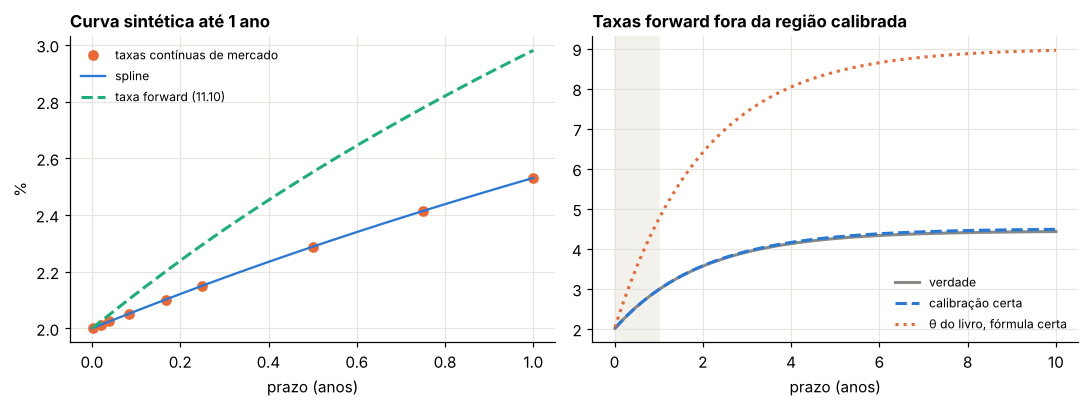

OK — com a fórmula do livro, o ajuste à curva até 1 ano é perfeito
OK — mas θ_r sai praticamente dobrado
OK — do ponto de partida do livro, o otimizador para longe do ajuste
OK — com a fórmula correta, θ_r é recuperado a menos de 5%
OK — o θ dobrado erra a taxa de 10 anos em mais de 50 pb


In [7]:
lin = tab3b.set_index("calibração")
p_livro = lin.loc["(11.6) do livro, outro início", ["κ_r", "θ_r", "σ_r"]].values
p_certo = lin.loc["fórmula correta, início do livro", ["κ_r", "θ_r", "σ_r"]].values
Tz = np.array([1.0, 2.0, 5.0, 10.0])
B_v = zcb_cir(T=Tz, **CIR_VERDADE)
B_livro = zcb_cir(r0_merc, *p_livro, Tz)
B_certo = zcb_cir(r0_merc, *p_certo, Tz)
tab3c = pd.DataFrame({"T": Tz, "B verdadeiro": B_v,
                      "θ do livro na fórmula certa": B_livro, "calibração certa": B_certo,
                      "erro do livro (pb de taxa)": 1e4 * (np.log(B_v) - np.log(B_livro)) / Tz})
tabela(tab3c)

fig, axs = plt.subplots(1, 2, figsize=(10, 3.8))
axs[0].plot(t_merc, 100 * y_merc, "o", color=LARANJA, label="taxas contínuas de mercado")
axs[0].plot(tn, 100 * sci.splev(tn, tck), color=AZUL, lw=1.5, label="spline")
axs[0].plot(tn, 100 * f_merc, "--", color=VERDE, label="taxa forward (11.10)")
axs[0].set_xlabel("prazo (anos)"); axs[0].set_ylabel("%")
axs[0].set_title("Curva sintética até 1 ano"); axs[0].legend(fontsize=8)
Tl = np.linspace(0.01, 10, 200)
axs[1].plot(Tl, 100 * fwd_cir(Tl, **CIR_VERDADE), color=CINZA, label="verdade")
axs[1].plot(Tl, 100 * fwd_cir(Tl, r0_merc, *p_certo), "--", color=AZUL, label="calibração certa")
axs[1].plot(Tl, 100 * fwd_cir(Tl, r0_merc, *p_livro), ":", color=LARANJA, label="θ do livro, fórmula certa")
axs[1].axvspan(0, 1, color="#f2f1ec", zorder=0)
axs[1].set_xlabel("prazo (anos)"); axs[1].set_title("Taxas forward fora da região calibrada")
axs[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

ok(lin.loc["(11.6) do livro, outro início", "RMSE (pb)"] < 0.5, "com a fórmula do livro, o ajuste à curva até 1 ano é perfeito")
ok(abs(p_livro[1] / CIR_VERDADE["theta"] - 2) < 0.05, "mas θ_r sai praticamente dobrado")
ok(lin.loc["(11.6) do livro, início do livro", "RMSE (pb)"] > 10, "do ponto de partida do livro, o otimizador para longe do ajuste")
ok(abs(p_certo[1] / CIR_VERDADE["theta"] - 1) < 0.05, "com a fórmula correta, θ_r é recuperado a menos de 5%")
ok(abs(tab3c["erro do livro (pb de taxa)"].iloc[-1]) > 50, "o θ dobrado erra a taxa de 10 anos em mais de 50 pb")

> **Nota sobre os dados do livro.** A taxa Eonia de 01/10/2014, usada como $r_0$, é **negativa** ($-0{,}032\%$). O CIR não admite taxas negativas: o termo $\sigma\sqrt{r}$ nem está definido. A fórmula fechada ainda devolve um número, mas ele deixa de ser um preço do modelo. Em ambientes de juros negativos usa-se um CIR deslocado (a extensão CIR++ de Brigo e Mercurio, citada na nota 13 do livro) ou outro modelo.

---
## 4. A função característica do Heston no livro

**Livro: §11.4.1 e §9.7.3**

O livro escreve a função característica com $c_1 = \kappa_v\theta_v$, $c_2 = -\sqrt{(\rho\sigma_vui - \kappa_v)^2 - \sigma_v^2(-ui - u^2)}$ e $c_3 = (\kappa_v - \rho\sigma_vui + c_2)/(\kappa_v - \rho\sigma_vui - c_2)$. Comparando com a nossa: $c_2 = -d$ e $c_3 = g$. Como $c_2 = -d$, os termos $e^{c_2T}$ são os $e^{-dT}$ que decaem: é a forma estável do Módulo 11.

> **Errata.** Na equação de $H_1$ impressa na §11.4.1, o logaritmo traz $1 - c_1e^{c_3T}$. O código (§9.7.3) usa $1 - c_3e^{c_2T}$, que é o correto.

### Laboratório 4 — O código do livro e a nossa função

In [8]:
def cf_heston_livro(u, T, r, kappa, theta, sigma, rho, v0, versao="código"):
    """Transcrição da §9.7.3 (com o r·iuT incluído); versao="impressa" usa o 1 - c1·e^{c3 T}."""
    c1 = kappa * theta
    c2 = -np.sqrt((rho * sigma * u * 1j - kappa) ** 2 - sigma**2 * (-u * 1j - u**2))
    c3 = (kappa - rho * sigma * u * 1j + c2) / (kappa - rho * sigma * u * 1j - c2)
    termo = (1 - c3 * np.exp(c2 * T)) if versao == "código" else (1 - c1 * np.exp(c3 * T))
    H1 = r * u * 1j * T + c1 / sigma**2 * ((kappa - rho * sigma * u * 1j + c2) * T
                                           - 2 * np.log(termo / (1 - c3)))
    H2 = (kappa - rho * sigma * u * 1j + c2) / sigma**2 * (1 - np.exp(c2 * T)) / (1 - c3 * np.exp(c2 * T))
    return np.exp(H1 + H2 * v0)


u = np.linspace(0, 50, 501) - 0.5j
v0, kv, tv, sv, rho = HESTON_VERDADE
r_, T_ = 0.03, 0.5
nossa = np.exp(1j * u * r_ * T_) * cf_heston(u, T_, v0, kv, tv, sv, rho)
livro = cf_heston_livro(u, T_, r_, kv, tv, sv, rho, v0)
impressa = cf_heston_livro(u, T_, r_, kv, tv, sv, rho, v0, "impressa")
print("maior diferença, código do livro × nossa:", f"{np.abs(livro - nossa).max():.1e}")
print("maior diferença, fórmula impressa × nossa:", f3(np.abs(impressa - nossa).max()))
ok(np.abs(livro - nossa).max() < 1e-12, "o código do livro é a forma estável, idêntica à nossa")
ok(np.abs(impressa - nossa).max() > 0.01, "a fórmula impressa de H1 dá outra função")

maior diferença, código do livro × nossa: 2.3e-16
maior diferença, fórmula impressa × nossa: 0,132
OK — o código do livro é a forma estável, idêntica à nossa
OK — a fórmula impressa de H1 dá outra função


---
## 5. Calibrar o Heston às 15 opções

**Livro: §11.4.2, §11.4.3, §11.6.2 e §11.6.3**

### 5.1 A estratégia do livro

O problema é minimizar (11.1) em $p = (\kappa_v, \theta_v, \sigma_v, \rho, v_0)$. A função objetivo não é convexa e pode ter vários mínimos locais. O livro usa dois passos:

1. **Busca em grade** (`brute`): avalia a função num reticulado grosso ($\kappa_v \in \{2{,}5;\ 7{,}5\}$, $\theta_v \in \{0{,}01; \dots; 0{,}04\}$, $\sigma_v \in \{0{,}05;\ 0{,}15;\ 0{,}25\}$, $\rho \in \{-0{,}75; \dots; 0\}$, $v_0 \in \{0{,}01;\ 0{,}02;\ 0{,}03\}$): 288 pontos.
2. **Busca local** (`fmin`, Nelder-Mead) a partir do melhor ponto da grade.

Restrições são impostas devolvendo um valor alto (500) fora da região admissível: $\kappa_v \ge 0$, $\theta_v \ge 0{,}005$, $\sigma_v \ge 0$, $|\rho| \le 1$ e a condição de Feller $2\kappa_v\theta_v \ge \sigma_v^2$.

Os juros entram como uma taxa constante por vencimento, $\bar r(T) = -\ln B_0(T)/T$, com $B_0$ do CIR calibrado. Pelo Módulo 11, isso é uma aproximação; em prazos de até seis meses ela é muito boa.

### Laboratório 5 — A calibração e o que sobra

In [9]:
GRADE_LIVRO = ((2.5, 10.6, 5.0), (0.01, 0.041, 0.01), (0.05, 0.251, 0.1), (-0.75, 0.01, 0.25), (0.01, 0.031, 0.01))
R_CAL = -np.log(zcb_cir(r0_merc, *p_certo, T_OP)) / T_OP      # juros da curva calibrada


def erro_h93(p, alvo, feller=True):
    kappa, theta, sigma, rho, v0 = p
    if kappa < 0 or theta < 0.005 or sigma < 0 or abs(rho) > 1 or v0 <= 0:
        return 500.0
    if feller and 2 * kappa * theta < sigma**2:
        return 500.0
    return np.mean((calls(S0, K_OP, T_OP, R_CAL, (v0, kappa, theta, sigma, rho)) - alvo) ** 2)


def calibra_h93(alvo, feller=True):
    p0 = brute(erro_h93, GRADE_LIVRO, args=(alvo, feller), finish=None)
    p = fmin(erro_h93, p0, args=(alvo, feller), xtol=1e-6, ftol=1e-6, maxiter=750, maxfun=900, disp=False)
    return p0, p, erro_h93(p, alvo, feller)


t0 = time.time()
p0_bates, p_bates, mse_bates = calibra_h93(C_MERC)
print(f"tempo: {time.time() - t0:.1f} s")
nomes = ["κ_v", "θ_v", "σ_v", "ρ", "v0"]
verd = [HESTON_VERDADE[i] for i in (1, 2, 3, 4, 0)]
tab5 = pd.DataFrame({"parâmetro": nomes, "melhor ponto da grade": p0_bates,
                     "calibrado": p_bates, "verdadeiro (Bates)": verd})
tabela(tab5)
print("EQM (11.1):", f3(mse_bates), "| folga de Feller 2κθ − σ²:", f3(2 * p_bates[0] * p_bates[1] - p_bates[2] ** 2))

tempo: 36.8 s


,parâmetro,melhor ponto da grade,calibrado,verdadeiro (Bates)
0,κ_v,"2,500","4,116","3,000"
1,θ_v,"0,040","0,045","0,040"
2,σ_v,"0,250","0,609","0,500"
3,ρ,"-0,750","-0,744","-0,700"
4,v0,"0,030","0,033","0,030"


EQM (11.1): 0,092 | folga de Feller 2κθ − σ²: 0,001


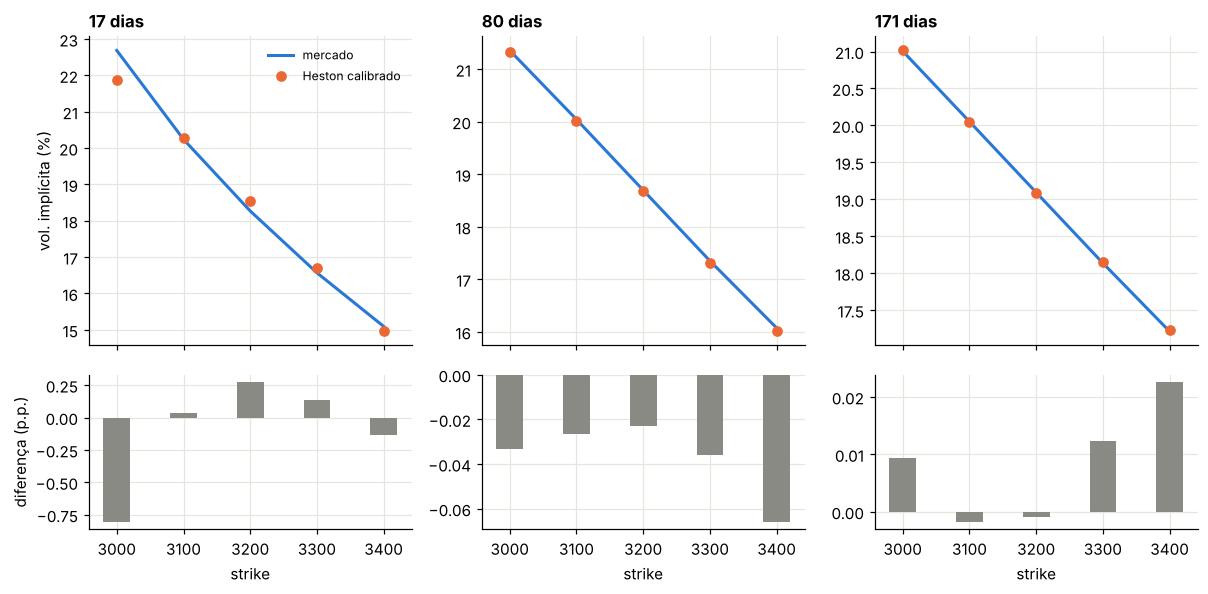

EQM por vencimento: {17: '0,223', 80: '0,043', 171: '0,011'}
OK — o Heston ajusta as 15 calls com EQM menor que 0,5 ponto²
OK — o maior erro de volatilidade fica abaixo de 1,5 p.p.
OK — o pior erro de volatilidade está no vencimento de 17 dias


In [10]:
C_cal = calls(S0, K_OP, T_OP, R_CAL, (p_bates[4], *p_bates[:4]))
IV_cal = np.array([vol_impl(c, S0, k, t, r) for c, k, t, r in zip(C_cal, K_OP, T_OP, R_OP)])
fig, axs = plt.subplots(2, 3, figsize=(11, 5.5), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
for j, d in enumerate(DIAS):
    m = slice(5 * j, 5 * j + 5)
    axs[0, j].plot(STRIKES, 100 * IV_MERC[m], "-", color=AZUL, label="mercado")
    axs[0, j].plot(STRIKES, 100 * IV_cal[m], "o", color=LARANJA, label="Heston calibrado")
    axs[0, j].set_title(f"{d} dias")
    axs[1, j].bar(STRIKES, 100 * (IV_cal[m] - IV_MERC[m]), width=40, color=CINZA)
    axs[1, j].set_xlabel("strike")
axs[0, 0].set_ylabel("vol. implícita (%)"); axs[1, 0].set_ylabel("diferença (p.p.)")
axs[0, 0].legend(fontsize=8)
plt.tight_layout(); plt.show()

res = pd.DataFrame({"dias": np.repeat(DIAS, 5), "erro (pontos)": C_cal - C_MERC,
                    "erro de vol. (p.p.)": 100 * (IV_cal - IV_MERC)})
eqm_prazo = res.groupby("dias")["erro (pontos)"].apply(lambda e: np.mean(e**2))
print("EQM por vencimento:", {k: f3(v) for k, v in eqm_prazo.items()})
ok(mse_bates < 0.5, "o Heston ajusta as 15 calls com EQM menor que 0,5 ponto²")
ok(np.abs(res["erro de vol. (p.p.)"]).max() < 1.5, "o maior erro de volatilidade fica abaixo de 1,5 p.p.")
ok(np.argmax(np.abs(res["erro de vol. (p.p.)"].values)) < 5, "o pior erro de volatilidade está no vencimento de 17 dias")

**O que aprendemos.** O ajuste é bom, como no livro (que obtém EQM de 0,307 com dados reais). Os resíduos não são aleatórios: o maior erro está no prazo mais curto, onde o skew do mercado é mais íngreme do que a volatilidade estocástica consegue gerar em 17 dias. É o papel dos saltos, que entram no Módulo 14. Repare também que os parâmetros calibrados **não** são os do Heston do modelo verdadeiro: o $\sigma_v$ e o $\rho$ absorvem parte do efeito dos saltos. E a folga de Feller impressa acima é praticamente zero: aqui também a solução parou na fronteira da restrição, como no livro (Seção 6).

---
## 6. O que os dados identificam

**Livro: §11.2.3 e §11.4.4 (degenerescência e indeterminação)**

Uma calibração com EQM baixo não garante parâmetros "certos". Duas perguntas:

* **Recuperação:** se o mercado fosse exatamente Heston, a calibração devolveria os parâmetros verdadeiros?
* **Perfil:** fixando um parâmetro em vários valores e recalibrando os outros, quanto o erro piora? Se piorar menos que o ruído das cotações, os dados não distinguem esses valores.

O modelo verdadeiro escolhido **viola** a condição de Feller: $2\kappa_v\theta_v = 0{,}24 < \sigma_v^2 = 0{,}25$. Isso é comum em calibrações a mercados de ações. A restrição de Feller do livro, então, proíbe justamente a verdade.

> **No livro.** Os parâmetros da §11.4.3 dão $2\kappa_v\theta_v - \sigma_v^2 = 2 \cdot 18{,}447 \cdot 0{,}026 - 0{,}978^2 \approx 0{,}003$: a solução está colada na fronteira de Feller. É o sinal de que a restrição está ativa e distorce o ajuste.

### Laboratório 6 — Recuperação, Feller e o perfil de $\kappa_v$

In [11]:
C_HESTON = np.round(calls(S0, K_OP, T_OP, R_CAL, HESTON_VERDADE, None, U_FINO), 1)
linhas = []
for feller in (True, False):
    _, p, e = calibra_h93(C_HESTON, feller)
    linhas.append(("com Feller" if feller else "sem Feller", *p, e, 2 * p[0] * p[1] - p[2] ** 2))
linhas.append(("verdadeiro", *verd, np.nan, 2 * 3.0 * 0.04 - 0.25))
tab6 = pd.DataFrame(linhas, columns=["calibração", *nomes, "EQM", "2κθ − σ²"])
tabela(tab6)

,calibração,κ_v,θ_v,σ_v,ρ,v0,EQM,2κθ − σ²
0,com Feller,"2,492","0,041","0,453","-0,727","0,030","0,023","0,000"
1,sem Feller,"2,992","0,040","0,498","-0,702","0,030","0,001","-0,009"
2,verdadeiro,"3,000","0,040","0,500","-0,700","0,030",n/d,"-0,010"


,κ_v fixo,θ_v,σ_v,ρ,v0,EQM
0,1,"0,058","0,434","-0,639","0,030","0,285"
1,2,"0,044","0,468","-0,672","0,030","0,060"
2,3,"0,040","0,499","-0,702","0,030","0,001"
3,5,"0,037","0,564","-0,747","0,030","0,164"
4,8,"0,035","0,696","-0,761","0,031","0,737"
5,12,"0,034","0,915","-0,739","0,031","1,649"
6,18,"0,034","1,306","-0,689","0,032","2,922"


tempo do perfil: 20.7 s


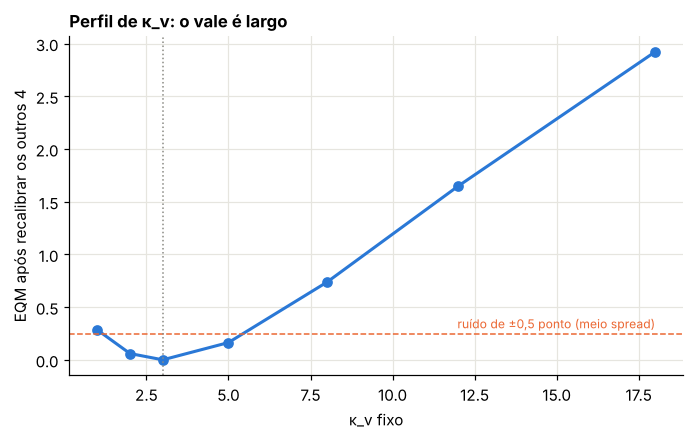

OK — sem Feller, a calibração recupera κ_v e σ_v verdadeiros
OK — com Feller, o EQM fica mais de 3 vezes maior
OK — e a solução com Feller fica na fronteira da restrição
valores de κ_v com EQM abaixo do ruído de meio spread: [2, 3, 5]
OK — κ_v entre 2 e 5 é compatível com cotações de spread de 1 ponto
OK — já v0 quase não se move ao longo do perfil: é bem identificado


In [12]:
t0 = time.time()
perfil = []
for kappa in [1, 2, 3, 5, 8, 12, 18]:
    def erro_fixo(q):
        theta, sigma, rho, v0 = q
        if theta < 0.001 or sigma < 0.01 or abs(rho) > 1 or v0 <= 0:
            return 500.0
        return np.mean((calls(S0, K_OP, T_OP, R_CAL, (v0, kappa, theta, sigma, rho)) - C_HESTON) ** 2)
    q = fmin(erro_fixo, [0.04, 0.5, -0.7, 0.03], xtol=1e-6, ftol=1e-8, maxiter=1500, maxfun=2000, disp=False)
    perfil.append((kappa, *q, erro_fixo(q)))
tab6b = pd.DataFrame(perfil, columns=["κ_v fixo", "θ_v", "σ_v", "ρ", "v0", "EQM"])
tabela(tab6b)
print(f"tempo do perfil: {time.time() - t0:.1f} s")

fig, ax = plt.subplots()
ax.plot(tab6b["κ_v fixo"], tab6b["EQM"], "o-", color=AZUL)
ax.axhline(0.25, ls="--", color=LARANJA, lw=1)
ax.text(18, 0.3, "ruído de ±0,5 ponto (meio spread)", ha="right", color=LARANJA, fontsize=8)
ax.axvline(3, color=CINZA, lw=1, ls=":")
ax.set_xlabel("κ_v fixo"); ax.set_ylabel("EQM após recalibrar os outros 4")
ax.set_title("Perfil de κ_v: o vale é largo")
plt.show()

t6 = tab6.set_index("calibração")
ok(abs(t6.loc["sem Feller", "κ_v"] - 3) < 0.3 and abs(t6.loc["sem Feller", "σ_v"] - 0.5) < 0.03,
   "sem Feller, a calibração recupera κ_v e σ_v verdadeiros")
ok(t6.loc["com Feller", "EQM"] > 3 * t6.loc["sem Feller", "EQM"], "com Feller, o EQM fica mais de 3 vezes maior")
ok(abs(t6.loc["com Feller", "2κθ − σ²"]) < 0.005, "e a solução com Feller fica na fronteira da restrição")
dentro = tab6b[tab6b["EQM"] < 0.25]["κ_v fixo"]
print("valores de κ_v com EQM abaixo do ruído de meio spread:", list(dentro))
ok(dentro.min() <= 2 and dentro.max() >= 5, "κ_v entre 2 e 5 é compatível com cotações de spread de 1 ponto")
ok(tab6b["v0"].std() < 0.002, "já v0 quase não se move ao longo do perfil: é bem identificado")

**O que aprendemos.**

* Sem Feller, com dados exatamente Heston, a calibração devolve os parâmetros verdadeiros: o método funciona.
* Com Feller, a calibração para na fronteira e piora o ajuste. A condição de Feller garante que $v$ não toca o zero, o que é conveniente para simulação (Módulo 12), mas não é uma exigência de ausência de arbitragem. Impô-la deve ser uma decisão consciente.
* Com vencimentos de até seis meses, $\kappa_v$ é **mal identificado**: entre 2 e 5, a diferença no ajuste fica abaixo do ruído de um spread típico. $\theta_v$ e $\sigma_v$ se ajustam para compensar. Já $v_0$, que domina o nível das volatilidades curtas, é bem identificado. O $\kappa_v = 18{,}4$ do livro é típico desse problema: um vale largo e uma solução empurrada para longe.
* Esse é o problema de **degenerescência** que o livro cita na §11.4.4. O Módulo 14 trata do remédio, a regularização.

---
## 7. Síntese

| Etapa | O que aprendemos |
|---|---|
| Por que calibrar | em mercado incompleto há um intervalo de preços; a calibração escolhe a medida que reprecifica o que é negociado |
| Função objetivo | (11.1) e (11.4) quase coincidem; (11.2) concentra peso nas opções baratas; a escolha faz parte do modelo |
| Curva de juros | taxas simples → contínuas → spline → taxas forward por (11.10); a fórmula do CIR precisa do fator 2 |
| Identificação dos juros | uma curva até 1 ano não fixa $\sigma_r$ e mal fixa $\kappa_r$; o $\theta_r$ vale para fora da região calibrada só se o modelo estiver certo |
| Heston | grade + busca local funciona; os resíduos no prazo curto pedem saltos |
| Identificação do Heston | $v_0$ bem identificado, $\kappa_v$ mal; a restrição de Feller pode distorcer o ajuste |

## 8. Erratas e notas sobre o capítulo 11 (primeira parte)

| Onde | O quê |
|---|---|
| Exemplo 4 (§11.2.1) | o limite é $\nu < 1/2$, não $1/4$; o intervalo de preços é $]4, 8[$, e não $]4, 9[$; e em $\nu = 1/4$ o preço seria 6, não "$1 + 8 = 9$" |
| Eq. (11.6) e código da §11.6.1 | falta o fator 2 no primeiro termo: o correto é $2\kappa_r\theta_r(e^{\gamma t} - 1)/D$; o $\theta_r$ calibrado sai dobrado |
| §11.6.1, ponto de partida | com a fórmula do livro, o Nelder-Mead a partir de $(1;\ 0{,}02;\ 0{,}1)$ pode parar longe do ajuste |
| §11.3.2, dados | a Eonia de 01/10/2014 ($-0{,}032\%$) é usada como $r_0$ do CIR, que não admite taxas negativas |
| §11.3.2, contagem | o texto chama a Euribor de "30/360", mas o código usa dias corridos/360 (real/360, que é a convenção da Euribor); os prazos das opções usam /365 |
| Eq. (11.7) | $B_t(T) = a\,e^{-b\,\mathbb{E}[r_t]}$ não é o preço esperado do título em $t$ (desigualdade de Jensen; ver Módulo 12) |
| §11.4.1, $H_1$ | o logaritmo impresso traz $1 - c_1e^{c_3T}$; o correto (e o código) é $1 - c_3e^{c_2T}$ |
| §11.4.3 | a solução ($\kappa_v = 18{,}447$) está na fronteira de Feller: a restrição está ativa |
| §11.6.2 | `options.ix` foi removido do pandas; use `.loc` |

## 9. Exercícios

**Exercício 1.** No Exemplo 4, suponha que a opção $A$ seja negociada a 6. Que medida $Q$ fica determinada? Qual o preço, por ela, de um derivativo que paga $(0, 0, 10)$?

<details><summary>Solução</summary>

$4 + 8\nu = 6 \Rightarrow \nu = 1/4$, logo $Q = (1/4, 1/2, 1/4)$. O derivativo vale $10 \cdot 1/4 = 2{,}5$. Com três ativos linearmente independentes, o mercado ficou completo e o preço é único.
</details>

**Exercício 2.** Mostre que, no CIR, $f(0, 0) = r_0$ e $f'(0, 0) = \kappa(\theta - r_0)$, e interprete.

<details><summary>Solução</summary>

Em $T = 0$: $E = 0$, $D = 2\gamma$, então $f = r_0 \cdot 4\gamma^2/(2\gamma)^2 = r_0$. Derivando em $T = 0$, o primeiro termo dá $2\kappa\theta\gamma/(2\gamma) = \kappa\theta$, e o segundo dá $r_0(\gamma - (\kappa + \gamma)) = -\kappa r_0$. A inclinação inicial da curva forward é o drift esperado da short rate: $\kappa(\theta - r_0)$. Isso também mostra por que a curva curta identifica bem o produto $\kappa\theta$, mas não $\kappa$ e $\theta$ separados.
</details>

**Exercício 3.** Calibre o CIR às **taxas contínuas** $y(t)$ nos 9 prazos, em vez das taxas forward do spline. Compare os parâmetros.

<details><summary>Solução</summary>

Minimize $\sum(y_i + \ln B^{CIR}(t_i)/t_i)^2$. Não há spline nem derivada, então não há ruído de interpolação; a derivada do spline amplifica o arredondamento das taxas, sobretudo nas pontas. Os parâmetros ficam próximos, e $\sigma_r$ continua não identificado.
</details>

**Exercício 4.** Refaça o Laboratório 5 com a função objetivo (11.2). O que acontece com o ajuste das opções de 171 dias?

<details><summary>Solução</summary>

O peso migra para as calls baratas de 17 dias e $K$ alto. O ajuste nelas melhora, e o das opções caras, de vega alto, piora em pontos. Se o uso do modelo for precificar algo parecido com as opções no dinheiro de prazo mais longo, (11.2) é a escolha errada.
</details>

**Exercício 5.** Acrescente ao mercado do Laboratório 6 o vencimento de 2 anos (5 strikes) e refaça o perfil de $\kappa_v$. O vale fica mais estreito?

<details><summary>Solução</summary>

Sim. A reversão à média só se manifesta em prazos comparáveis a $1/\kappa_v$ (um terço de ano para $\kappa_v = 3$). Com 2 anos, a estrutura a termo das volatilidades no dinheiro passa a revelar a velocidade de reversão, e $\kappa_v$ e $\theta_v$ se separam.
</details>

In [13]:
print(f"Módulo 13 concluído: {_checks['n']} verificações aprovadas.")

Módulo 13 concluído: 24 verificações aprovadas.
